In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [ ]:
df = pd.read_csv("creditcard.csv")
# print(df.head())
# print(df.columns)

In [ ]:
X = df.drop("Class", axis=1)
y = df["Class"]
# print(y_true.dtype)
# print(X.dtype)

In [ ]:
# normalizes dataset features by shifting them to a mean of 0 and a standard deviation of 1 (also known as Z-score normalization).



scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

In [ ]:
class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=1000):
        
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.loss_history = []   #Its primary purpose is to create a dedicated, empty container for every individual object (instance) created from that class. As the program runs, you can append data to this list to keep track of changes, actions, or states over time.


    # defining sigmoid function
    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))


    # computing loss function
    def compute_loss(self, y, predictions):
        eps = 1e-15
        predictions = np.clip(
            predictions,
            eps,
            1 - eps
        )
        loss = -np.mean(
            y * np.log(predictions) +
            (1 - y) * np.log(1 - predictions)
        )
        return loss
    
    # fit function
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        for epoch in range(self.epochs):

            # Forward propagation
            # calculate the linear combination of input features and weights, plus a bias term,
            linear = np.dot(X, self.weights) + self.bias

            predictions = self.sigmoid(linear)

            # Calculate error
            error = predictions - y

            # Calculate gradients
            # Calculating the matrix multiplication for the transpose matrix of x and the error matix then diving it by the number of total samples
            dw = np.dot(X.T, error) / n_samples
            db = np.mean(error)

            # Gradient Descent
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # Calculate and store loss
            loss = self.compute_loss(y, predictions)

            self.loss_history.append(loss)

            if epoch % 100 == 0:
                print(
                    f"Epoch {epoch:4d} | Loss = {loss:.6f}"
                )

        return self

    def predict_proba(self, X):

        linear = np.dot(X, self.weights) + self.bias

        return self.sigmoid(linear)

    def predict(self, X, threshold=0.5):

        probabilities = self.predict_proba(X)

        return (probabilities >= threshold).astype(int)

In [ ]:
model_scratch = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=1000
)

In [ ]:
model_scratch.fit(X_train, y_train)

y_pred = model_scratch.predict(X_test)
y_prob = model_scratch.predict_proba(X_test)

In [ ]:
print("Logistic Regression From Scratch:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
plt.figure(figsize=(8, 5))
plt.plot(model_scratch.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Gradient Descent Convergence")
plt.grid()
plt.show()

      Metric   Scratch  Scikit-learn
0   Accuracy  0.998876      0.998876
1  Precision  0.783333      0.783333
2     Recall  0.479592      0.479592
3   F1 Score  0.594937      0.594937
4    ROC-AUC  0.981567      0.981567
5     PR-AUC  0.721377      0.721377


Text(0.5, 1.0, 'Convergence Behavior')

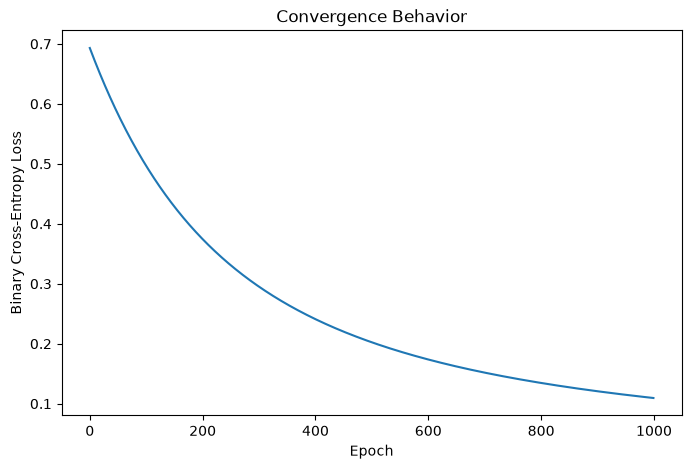

In [21]:
# Compare its performance and convergence behavior with Scikit-learn's implementation. 

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Scratch": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ],

    "Scikit-learn": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ]
})

print(comparison)

model_scratch.loss_history

plt.figure(figsize=(8, 5))

plt.plot(
    model_scratch.loss_history,
    label="Scratch Gradient Descent"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Convergence Behavior")